In [1]:
import ctypes
import json, os, random
from pathlib import Path
import numpy as np
import pandas as pd
try:
    import nvidia
    cusolver_lib = Path(next(iter(nvidia.__path__))) / 'cusolver' / 'lib' / 'libcusolver.so.11'
    if cusolver_lib.is_file():
        ctypes.CDLL(str(cusolver_lib), mode=ctypes.RTLD_GLOBAL)
except (ImportError, OSError, StopIteration) as error:
    print(f'cuSOLVER preload skipped: {error}')
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

DATA_DIR = Path("dataset")
OUT = Path("runs/mobilenetv3large")
MAX_PER_CLASS = 1000
MAX_VAL_PER_CLASS = 300
EPOCHS = 8
FINE_TUNE_EPOCHS = 8
BATCH = 64
SEED = 42
IMG = (224, 224)

OUT.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices("GPU"))

I0000 00:00:1794037659.672144    4601 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794037659.725575    4601 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794037710.312255    4601 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
class_names = sorted(d.name for d in (DATA_DIR / "train").iterdir() if d.is_dir())
n_classes = len(class_names)

def list_split(split, cap):
    rng = random.Random(SEED)
    paths, labels = [], []
    for i, c in enumerate(class_names):
        d = DATA_DIR / split / c
        if not d.is_dir():
            continue
        files = sorted(p for p in d.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        if cap and len(files) > cap:
            files = rng.sample(files, cap)
        paths += [str(p) for p in files]
        labels += [i] * len(files)
    return paths, np.array(labels, dtype=np.int32)

def make_ds(paths, labels, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(min(len(paths), 20000), seed=SEED)
    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        return tf.image.resize(img, IMG), y
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

tr_p, tr_y = list_split("train", MAX_PER_CLASS)
va_p, va_y = list_split("val", MAX_VAL_PER_CLASS)
te_p, te_y = list_split("test", 0)
train_ds, val_ds, test_ds = make_ds(tr_p, tr_y, True), make_ds(va_p, va_y, False), make_ds(te_p, te_y, False)

counts = np.bincount(tr_y, minlength=n_classes)
class_weight = {i: len(tr_y) / (n_classes * max(int(c), 1)) for i, c in enumerate(counts)}
(OUT / "class_names.json").write_text(json.dumps(class_names, indent=2))
print(n_classes, "classes | train", len(tr_p), "| val", len(va_p), "| test", len(te_p))

I0000 00:00:1794037746.539346    4601 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


46 classes | train 44284 | val 13115 | test 19218


In [3]:
L = tf.keras.layers
base = tf.keras.applications.MobileNetV3Large(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

augment = tf.keras.Sequential([
    L.RandomFlip("horizontal_and_vertical"),
    L.RandomRotation(0.2),
    L.RandomZoom(0.25),
    L.RandomTranslation(0.1, 0.1),
    L.RandomContrast(0.25),
    L.RandomBrightness(0.2, value_range=(0, 255)),
])

inputs = tf.keras.Input(shape=IMG + (3,))
x = augment(inputs)
x = base(x, training=False)
x = L.GlobalAveragePooling2D()(x)
x = L.Dropout(0.3)(x)
outputs = L.Dense(n_classes, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

In [4]:
def compile_model(lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(patience=1, factor=0.3),
    ]

compile_model(1e-3)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks(), class_weight=class_weight)

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
compile_model(1e-5)
done = len(h1.history["loss"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=done + FINE_TUNE_EPOCHS, initial_epoch=done,
               callbacks=callbacks(), class_weight=class_weight)

Epoch 1/8


/mnt/c/Vivek/clg/code/Plant_Disease_Detector-/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794037753.362103    5111 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1794037753.466646    5108 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109376 bytes after encountering the first element of size 67109376 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce ele

692/692 ━━━━━━━━━━━━━━━━━━━━ 171s 216ms/step - accuracy: 0.6905 - loss: 1.1101 - val_accuracy: 0.8566 - val_loss: 0.4922 - learning_rate: 0.0010
Epoch 2/8
  2/692 ━━━━━━━━━━━━━━━━━━━━ 56s 83ms/step - accuracy: 0.9062 - loss: 0.4148  

W0000 00:00:1794037921.820451    5108 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109376 bytes after encountering the first element of size 67109376 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


692/692 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8561 - loss: 0.4745

W0000 00:00:1794037981.731092    5618 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


... (41 outputs left out)

W0000 00:00:1794039178.922750   10384 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1794039179.051726    7900 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109376 bytes after encountering the first element of size 67109376 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


692/692 ━━━━━━━━━━━━━━━━━━━━ 96s 136ms/step - accuracy: 0.9226 - loss: 0.2323 - val_accuracy: 0.9339 - val_loss: 0.1994 - learning_rate: 1.0000e-05
Epoch 16/16


W0000 00:00:1794039275.019899   10724 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1794039275.235614    7900 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109376 bytes after encountering the first element of size 67109376 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


692/692 ━━━━━━━━━━━━━━━━━━━━ 108s 153ms/step - accuracy: 0.9276 - loss: 0.2215 - val_accuracy: 0.9350 - val_loss: 0.1953 - learning_rate: 1.0000e-05


W0000 00:00:1794039384.111105    4601 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


301/301 ━━━━━━━━━━━━━━━━━━━━ 28s 86ms/step
{
  "test_accuracy": 0.9393,
  "test_macro_f1": 0.9278,
  "n_train": 44284,
  "n_val": 13115,
  "n_test": 19218,
  "params_millions": 3.04,
  "model_size_mb": 26.0,
  "max_per_class": 1000,
  "epochs": 8,
  "fine_tune_epochs": 8
}

10 weakest classes:
                                               precision  recall  f1-score  support
Rice___Brown_Spot                                 0.4746  0.5091    0.4912     55.0
Rice___Leaf_Blast                                 0.8305  0.6364    0.7206     77.0
Tomato___Target_Spot                              0.7694  0.7374    0.7531    457.0
Tomato___Early_blight                             0.9428  0.7208    0.8170    480.0
Tomato___Spider_mites_Two-spotted_spider_mite     0.7561  0.9195    0.8299    435.0
Tomato___Septoria_leaf_spot                       0.7988  0.9106    0.8510    436.0
Tomato___Late_blight                              0.8220  0.8877    0.8536    463.0
Corn___Cercospora_leaf_spot_Gray_

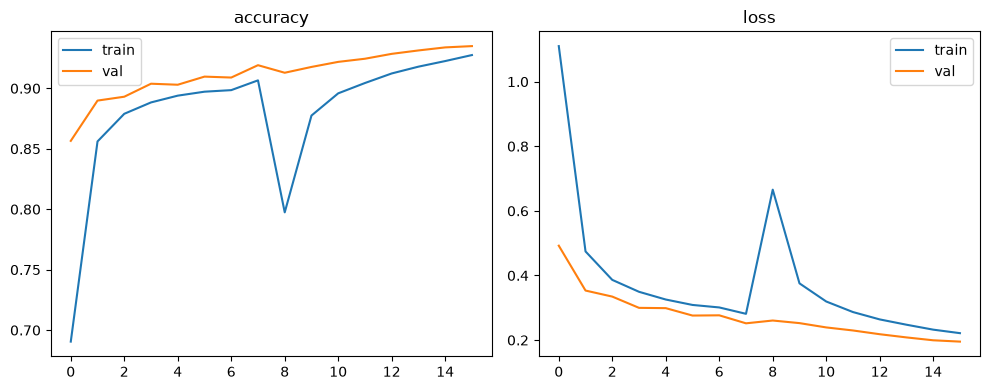

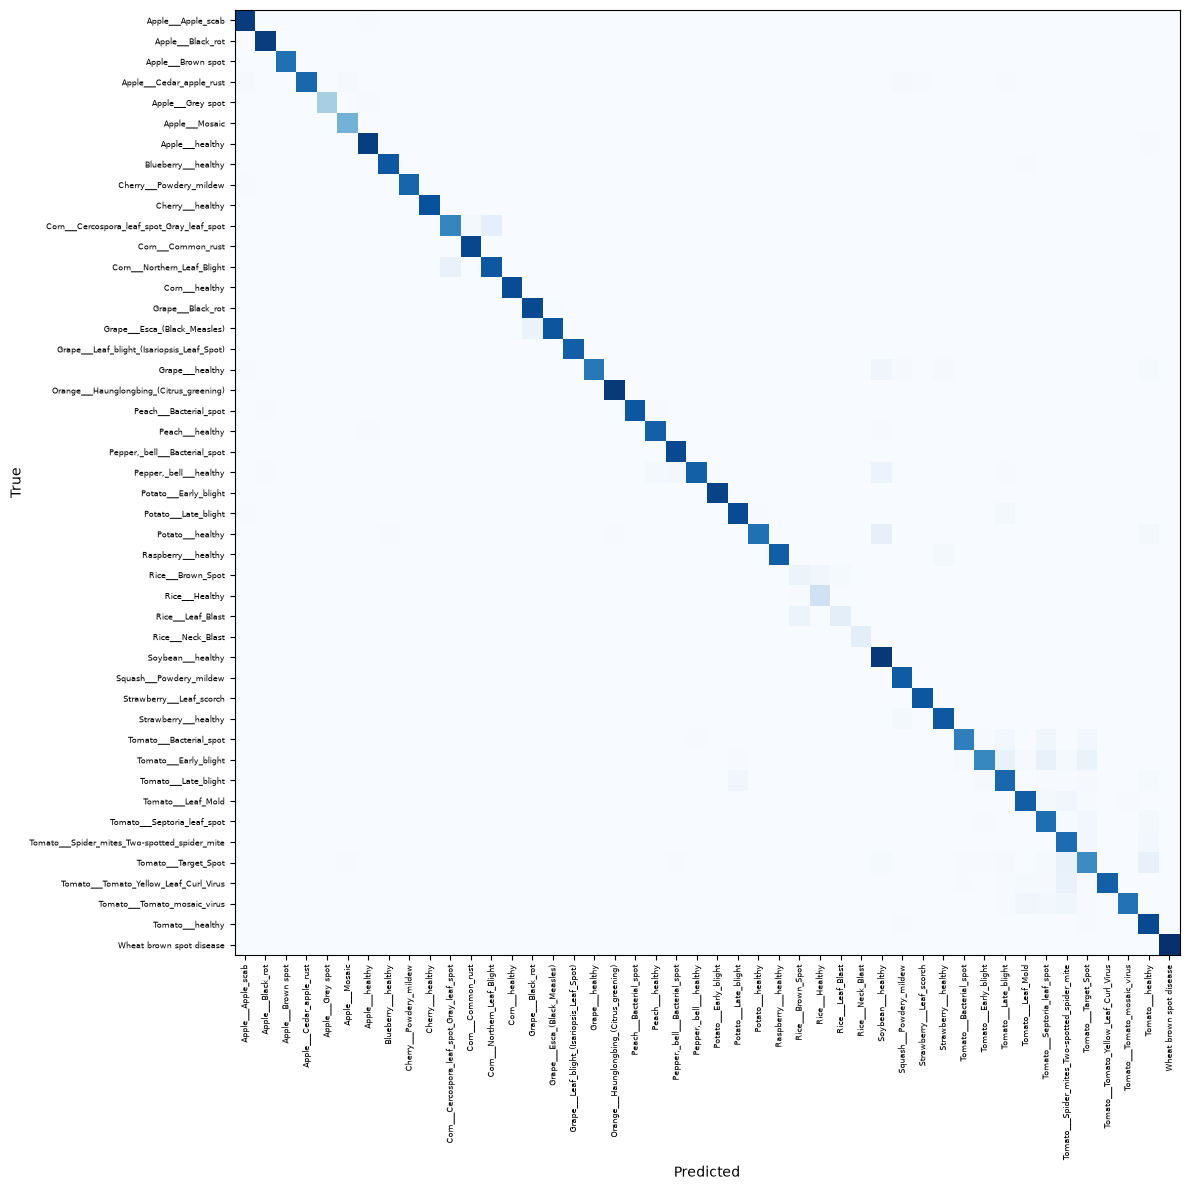

: 

In [ ]:
y_pred = model.predict(test_ds).argmax(1)
labels = list(range(n_classes))
report = classification_report(te_y, y_pred, labels=labels, target_names=class_names, zero_division=0, output_dict=True)
per_class = pd.DataFrame({c: report[c] for c in class_names}).T.round(4)
per_class.to_csv(OUT / "per_class_f1.csv")

model.save(OUT / "model.keras")
results = {
    "test_accuracy": round(float(report["accuracy"]), 4),
    "test_macro_f1": round(float(report["macro avg"]["f1-score"]), 4),
    "n_train": len(tr_p), "n_val": len(va_p), "n_test": len(te_p),
    "params_millions": round(model.count_params() / 1e6, 2),
    "model_size_mb": round(os.path.getsize(OUT / "model.keras") / 1e6, 1),
    "max_per_class": MAX_PER_CLASS, "epochs": EPOCHS, "fine_tune_epochs": FINE_TUNE_EPOCHS,
}
(OUT / "results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))
print("\n10 weakest classes:")
print(per_class.sort_values("f1-score").head(10).to_string())

hist = {k: h1.history[k] + h2.history[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, k in zip(ax, ("accuracy", "loss")):
    a.plot(hist[k], label="train")
    a.plot(hist["val_" + k], label="val")
    a.set_title(k)
    a.legend()
fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=150)
plt.show()

cm = confusion_matrix(te_y, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(labels, class_names, rotation=90, fontsize=6)
ax.set_yticks(labels, class_names, fontsize=6)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.show()